# DM-2 : Boosting et cartes de saillance

Description rapide

In [150]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from pyparsing import results
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
seed =42

## 0. Import du dataset MNIST

### A faire
- Des matrices de confusion manquent. Le sujet en demande une « pour chaque combinaison de paramètres ». Vous n’en tracez pas pour les cas binaires, et pour le multiclasse vous n’en avez qu’une par type de classifieur faible.
- Le nombre d’étapes de boosting n’est pas vraiment étudié. Le meilleur n_estimators vaut toujours 100, la borne haute de votre grille : l’accuracy augmente donc encore à 100. Le sujet demande de faire varier ce paramètre. Une courbe accuracy en fonction de n_estimators pour chaque classifieur faible serait plus parlante que le seul meilleur score. Ces valeurs sont déjà calculées dans grid.cv_results_["mean_test_score"].
- Le cas 0–4 contre 5–9, cité dans le sujet, n’est pas encore traité.

### A corriger
- La première matrice de confusion a pour texte alternatif « décision stump », alors que le modèle utilise des arbres de profondeur 20.
- Dans la grid search, le titre de chaque matrice affiche l’accuracy de validation croisée, alors que la matrice est calculée sur le jeu de test.

Pour AdaBoost, il n'est pas vraiment nécessaire de diviser X par . Cependant, cela devient nécessaire pour le perceptron.

Par ailleurs, nous n'utilisons pas StandardScaler pour éviter d'amplifier le bruit du fond (variance presque nulle) et éviter toute fuite de données de test à train.

In [151]:
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X = X / 255.0
y = y.astype(int)

(70000, 784) (70000,)


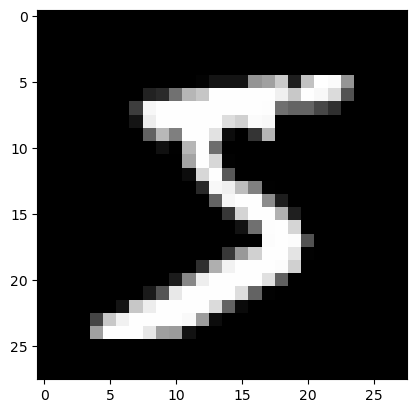

In [109]:
print(X.shape, y.shape)
plt.imshow(X[0, :].reshape(28, 28), cmap="Greys_r")

In [ ]:
np.unique_counts(y)

- Le jeu de données comprend 70000 images aplaties de taille (1, 784) ((28,28) à l'origine).
- Ce sont des chiffres manuscrits entre 0 et 9, les classes peuvent être considérées étant équilibrées.

## 1. Utilisation d’un algorithme de boosting sur de la reconnaissance de chiﬀres manuscrits

Séparation du dataset en set d'entrainnement et de test. \
75 % en entrainnement et 25% en test, car nous avons un grand nombre d'images.

In [152]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)

### A. Première modélisation

Première modelisation avec Adaboost :
- Abre de décision (profondeur maximal de 20)
- nombre d'estimateur : 20
- learning rate : 0.5 \
\
Avec une profondeur macimale de , nous ne pouvons pas vraiment dire que c'est un apprenant faible. Nous avons repris les hyperparamètres du site Medium donné dans le sujet du DM.

In [153]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

Tree_adaboost = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=20),
                                  n_estimators=20,
                                  learning_rate=0.5,
                                  random_state=seed)

Tree_adaboost.fit(X_train, y_train)

Tree_adaboost_score = Tree_adaboost.score(X_test, y_test)
print(f"AdaBoost score: {Tree_adaboost_score}")

KeyboardInterrupt: 

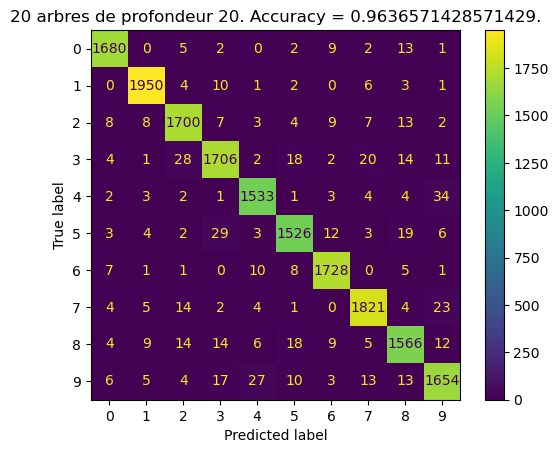

In [112]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm_Tree_adaboost = confusion_matrix(y_test, Tree_adaboost.predict(X_test))
cm_Tree_adaboost_disp = ConfusionMatrixDisplay(cm_Tree_adaboost)
cm_Tree_adaboost_disp.plot()
cm_Tree_adaboost_disp.ax_.set_title(f"20 arbres de profondeur 20. Accuracy = {Tree_adaboost_score}.")
plt.savefig("images/cm_AdaBoost/cm_First_Tree_adaboost.png", dpi=300, bbox_inches="tight")

<img src="images/cm_AdaBoost/cm_First_Tree_adaboost.png" alt= "Matrice de confusion décision stump" width="500">

Avec ce premier modèle, nous obtenons un score d'exactitude (accuracy) de 0,9637 en test. La matrice de confusion montre de bons résultats avec une majorité de bons classements, surtout pour les 1.

La matrice de confusion se lit par ligne : chaque ligne correspond à la vraie classe et chaque colonne à la classe prédite. La grande majorité des images se trouve sur la diagonale. Les classes étant de tailles légèrement différentes, on compare les taux de bonne classification (rappel) plutôt que les effectifs bruts :

- les mieux reconnus sont les 1, les 6 et les 0 ;
- les moins bien reconnus sont les 9, les 8 et les 3. \
\
Les principales confusions sont :

- entre les 4 et les 9, dans les deux sens (27 + 34 = 61 erreurs), un 4 fermé en haut ressemblant à un 9 ;
- des 3 prédits comme des 2 (35 erreurs) ;
- des 5 prédits comme des 3 (47 erreurs), ces deux chiffres partagent effectivement la même boucle inférieure.

### B. Gridsearch en variant les classifier faibles

Stratification pour la cross-validation.

In [154]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
folds = skf.split(X_train, y_train)

Réglage des paramètres à tester en GridSearch.

In [168]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d3": DecisionTreeClassifier(max_depth=3),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [1, 2, 5, 10, 20, 50]}

Nous réalisons la cross-validation GridSearch :

In [115]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

results = []
best_results = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_train, y_train)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    y_pred = best.predict(X_test)
    acc_test = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. Accuracy = {acc_test}.")
    plt.savefig(f"images/cm_AdaBoost/cm_{estimator_name}.png", dpi=300, bbox_inches="tight")
    plt.close()

[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7896), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7896), 'n_estimators': 50}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.8458666666666665), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7896), 'n_estimators': 50}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.8458666666666665), 'n_estimators': 50}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.9065333333333333), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7

Construction d'un dataframe avec les resultats de la recherche.

In [120]:
df_cv_all = pd.concat(results, ignore_index=True)
df_accuracy = (df_cv_all.rename(columns={"param_n_estimators": "n_estimators", "mean_test_score": "accuracy_cv", "std_test_score": "std_cv"})[["estimator", "n_estimators", "accuracy_cv", "std_cv"]].sort_values(["estimator", "n_estimators"]).reset_index(drop=True))
df_accuracy.to_csv("results/AdaBoost_cv_results.csv", sep=";") # transformation en csv
df_accuracy

,estimator,n_estimators,accuracy_cv,std_cv
0,perceptron,1,0.859581,0.015488
1,perceptron,2,0.859581,0.015488
2,perceptron,5,0.848305,0.007940
3,perceptron,10,0.850419,0.005239
4,perceptron,20,0.844095,0.003330
5,perceptron,50,0.849448,0.004109
6,stump,1,0.197067,0.000802
7,stump,2,0.184210,0.000664
8,stump,5,0.217200,0.044985
9,stump,10,0.271390,0.027471


Creation d'un dataframe avec les meilleurs résultats de la recherche.

In [121]:
df_best_results = pd.DataFrame(best_results, columns=["estimator", "accuracy", "n_estimators"])
df_best_results.to_csv("results/AdaBoost_cv_best_results.csv", sep=";") # transformation en csv
df_best_results

,estimator,accuracy,n_estimators
0,stump,0.637314,50
1,tree_d2,0.789600,50
2,tree_d3,0.845867,50
3,tree_d5,0.906533,50
4,tree_d20,0.965848,50
5,perceptron,0.859581,1


<img src="images/cm_AdaBoost/cm_stump.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron.png" alt= "Matrice de confusion perceptron" width="500">

## Il faut revoir ça !
Influence du nombre d'étapes de boosting

Dans la grid search ci-dessus, le meilleur n_estimators est toujours la borne haute de la grille : l'accuracy n'a pas encore atteint son plateau. Nous étudions donc le nombre d'étapes de boosting jusqu'à N_MAX = 100.

Plutôt que de réentraîner un modèle pour chaque valeur, nous entraînons un seul AdaBoost à N_MAX étapes par classifieur faible, puis nous utilisons staged_predict, qui donne les prédictions après 1, 2, …, N_MAX étapes. Avec le même random_state, les k premières étapes d'un modèle à 100 étapes sont exactement celles d'un modèle entraîné avec n_estimators = k. Un seul entraînement donne donc :

la courbe de l'accuracy test en fonction du nombre d'étapes, pour chaque classifieur faible ;
une matrice de confusion pour chaque combinaison (classifieur faible, n_estimators), avec n_estimators dans N_LIST.
Aucun hyperparamètre n'est choisi sur le jeu de test : ces accuracies servent seulement à comparer les configurations.

La même fonction est réutilisée pour les classes binaires (partie C).

Evolution de l'accuracy.

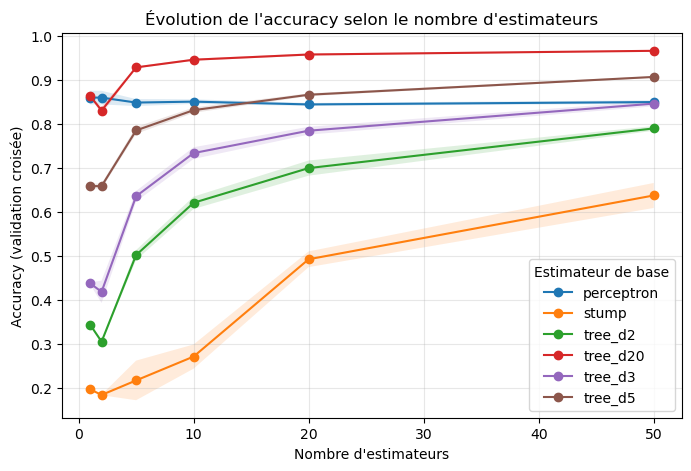

In [122]:
fig, ax = plt.subplots(figsize=(8, 5))

for estimator_name, sub in df_accuracy.groupby("estimator"):
    ax.plot(sub["n_estimators"], sub["accuracy_cv"],
            marker="o", label=estimator_name)
    ax.fill_between(sub["n_estimators"],
                    sub["accuracy_cv"] - sub["std_cv"],
                    sub["accuracy_cv"] + sub["std_cv"],
                    alpha=0.15)

ax.set_xlabel("Nombre d'estimateurs")
ax.set_ylabel("Accuracy (validation croisée)")
ax.set_title("Évolution de l'accuracy selon le nombre d'estimateurs")
ax.legend(title="Estimateur de base")
ax.grid(True, alpha=0.3)
plt.savefig("images/graphs/accuracy_vs_n_estimators.png", dpi=300, bbox_inches="tight")
plt.show()

<img src="images/graphs/accuracy_vs_n_estimators.png" alt= "Matrice de confusion perceptron" width="500">

## Il faut revoir ça !
Analyse (à compléter après exécution) :

valeur de n_estimators à partir de laquelle chaque courbe atteint son plateau ;
classifieurs faibles qui continuent à progresser à 100 étapes (probablement les plus faibles : stump, arbres de profondeur 2 et 3) ;
évolution des confusions 4/9, 3/5 et 3/8 quand n_estimators augmente.

### C. Etude de classes binaires

Nous étudions ici des problèmes binaires :

9 contre 4 et 5 contre 3 : les deux paires les plus confondues par le premier modèle (partie A) ;
8 contre 3 : la paire citée dans le sujet, également la plus simple à interpréter pour les cartes de saillance de la partie 2 ;
5–9 contre 0–4 : le cas « groupes de chiffres » cité dans le sujet.
Pour que les résultats soient comparables avec le cas multiclasse, nous gardons le même découpage train/test que précédemment : nous filtrons X_train et X_test au lieu de refaire un train_test_split (aucune image de test du multiclasse ne se retrouve ainsi dans un train binaire).

Pour chaque cas, nous faisons varier le classifieur faible et le nombre d'étapes de boosting, avec la fonction etudier_n_estimators définie en partie B : une matrice de confusion par combinaison, puis la courbe de l'accuracy test. Par convention, la classe 1 est la première citée (9 dans « 9 contre 4 »).

#### 1. 9 vs 4

In [169]:
mask_train_9v4 = (y_train == 9) | (y_train == 4)
mask_test_9v4  = (y_test  == 9) | (y_test  == 4)
X_9v4_train,  y_9v4_train  = X_train[mask_train_9v4], (y_train[mask_train_9v4] == 9).astype(int)
X_9v4_test, y_9v4_test = X_test[mask_test_9v4], (y_test[mask_test_9v4] == 9).astype(int)
print(np.unique_counts(y_9v4_train), np.unique_counts(y_9v4_test))

UniqueCountsResult(values=array([0, 1]), counts=array([5237, 5206])) UniqueCountsResult(values=array([0, 1]), counts=array([1587, 1752]))


In [171]:
from sklearn.metrics import f1_score

results_9v4 = []
best_results_9v4 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="f1", cv=skf, n_jobs=-1)

    grid.fit(X_9v4_train, y_9v4_train)
    f1 = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results_9v4.append({"estimator" : estimator_name, "f1_score" : f1, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results_9v4)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results_9v4.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    y_pred = best.predict(X_9v4_test)
    score = f1_score(y_9v4_test, y_pred)
    cm = confusion_matrix(y_9v4_test, y_pred)
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. f1_score = {score}.")
    plt.savefig(f"images/cm_AdaBoost/cm_{estimator_name}_9v4.png", dpi=300, bbox_inches="tight")
    plt.close()

[{'estimator': 'stump', 'f1_score': np.float64(0.9424963138045944), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9424963138045944), 'n_estimators': 50}, {'estimator': 'tree_d2', 'f1_score': np.float64(0.9753394915617803), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9424963138045944), 'n_estimators': 50}, {'estimator': 'tree_d2', 'f1_score': np.float64(0.9753394915617803), 'n_estimators': 50}, {'estimator': 'tree_d3', 'f1_score': np.float64(0.9812723737380283), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9424963138045944), 'n_estimators': 50}, {'estimator': 'tree_d2', 'f1_score': np.float64(0.9753394915617803), 'n_estimators': 50}, {'estimator': 'tree_d3', 'f1_score': np.float64(0.9812723737380283), 'n_estimators': 50}, {'estimator': 'tree_d5', 'f1_score': np.float64(0.9864865390093593), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9424963138045944), 'n_estimators': 50}, {'estimator': '

<img src="images/cm_AdaBoost/cm_stump_9v4.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2_9v4.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3_9v4.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5_9v4.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20_9v4.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron_9v4.png" alt= "Matrice de confusion perceptron" width="500">

In [177]:
df_cv_all_9v4 = pd.concat(results_9v4, ignore_index=True)
df_accuracy_9v4 = (df_cv_all_9v4.rename(columns={"param_n_estimators": "n_estimators", "mean_test_score": "f1_score_cv", "std_test_score": "std_cv"})[["estimator", "n_estimators", "f1_score_cv", "std_cv"]].sort_values(["estimator", "n_estimators"]).reset_index(drop=True))
df_accuracy_9v4.to_csv("results/AdaBoost_cv_results_9v4.csv", sep=";") # transformation en csv
df_accuracy_9v4

,estimator,n_estimators,f1_score_cv,std_cv
0,perceptron,1,0.945599,0.025841
1,perceptron,2,0.950914,0.015409
2,perceptron,5,0.957691,0.003300
3,perceptron,10,0.956991,0.002745
4,perceptron,20,0.957119,0.002671
5,perceptron,50,0.957171,0.003105
6,stump,1,0.867837,0.004352
7,stump,2,0.867837,0.004352
8,stump,5,0.869300,0.004821
9,stump,10,0.902331,0.007357


In [178]:
df_best_results_9v4 = pd.DataFrame(best_results_9v4, columns=["estimator", "f1_score", "n_estimators"])
df_best_results_9v4.to_csv("results/AdaBoost_cv_best_results_9v4.csv", sep=";") # transformation en csv
df_best_results_9v4

,estimator,f1_score,n_estimators
0,stump,0.942496,50
1,tree_d2,0.975339,50
2,tree_d3,0.981272,50
3,tree_d5,0.986487,50
4,tree_d20,0.985084,50
5,perceptron,0.957691,5


#### 2. 5 vs 3

In [172]:
mask_train_5v3 = (y_train == 5) | (y_train == 3)
mask_test_5v3  = (y_test  == 5) | (y_test  == 3)
X_5v3_train, y_5v3_train  = X_train[mask_train_5v3], (y_train[mask_train_5v3] == 5).astype(int)
X_5v3_test, y_5v3_test = X_test[mask_test_5v3], (y_test[mask_test_5v3] == 5).astype(int)
print(np.unique_counts(y_5v3_train), np.unique_counts(y_5v3_test))

UniqueCountsResult(values=array([0, 1]), counts=array([5335, 4706])) UniqueCountsResult(values=array([0, 1]), counts=array([1806, 1607]))


In [174]:
results_5v3 = []
best_results_5v3 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_5v3_train, y_5v3_train)
    f1 = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results_5v3.append({"estimator" : estimator_name, "f1_score" : f1, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results_5v3)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results_5v3.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    y_pred = best.predict(X_5v3_test)
    score = f1_score(y_5v3_test, y_pred)
    cm = confusion_matrix(y_5v3_test, y_pred)
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. f1_score = {score}.")
    plt.savefig(f"images/cm_AdaBoost/cm_{estimator_name}_5v3.png", dpi=300, bbox_inches="tight")
    plt.close()

[{'estimator': 'stump', 'f1_score': np.float64(0.9332740218816126), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9332740218816126), 'n_estimators': 50}, {'estimator': 'tree_d2', 'f1_score': np.float64(0.9711191570204993), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9332740218816126), 'n_estimators': 50}, {'estimator': 'tree_d2', 'f1_score': np.float64(0.9711191570204993), 'n_estimators': 50}, {'estimator': 'tree_d3', 'f1_score': np.float64(0.9826714545501419), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9332740218816126), 'n_estimators': 50}, {'estimator': 'tree_d2', 'f1_score': np.float64(0.9711191570204993), 'n_estimators': 50}, {'estimator': 'tree_d3', 'f1_score': np.float64(0.9826714545501419), 'n_estimators': 50}, {'estimator': 'tree_d5', 'f1_score': np.float64(0.9896426241276804), 'n_estimators': 50}]
[{'estimator': 'stump', 'f1_score': np.float64(0.9332740218816126), 'n_estimators': 50}, {'estimator': '

<img src="images/cm_AdaBoost/cm_stump_5v3.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2_5v3.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3_5v3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5_5v3.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20_5v3.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron_5v3.png" alt= "Matrice de confusion perceptron" width="500">

In [175]:
df_cv_all_5v3 = pd.concat(results_5v3, ignore_index=True)
df_accuracy_5v3 = (df_cv_all_5v3.rename(columns={"param_n_estimators": "n_estimators", "mean_test_score": "f1_score_cv", "std_test_score": "std_cv"})[["estimator", "n_estimators", "f1_score_cv", "std_cv"]].sort_values(["estimator", "n_estimators"]).reset_index(drop=True))
df_accuracy_5v3.to_csv("results/AdaBoost_cv_results_5v3.csv", sep=";") # transformation en csv
df_accuracy_5v3

,estimator,n_estimators,f1_score_cv,std_cv
0,perceptron,1,0.943535,0.019786
1,perceptron,2,0.943535,0.019786
2,perceptron,5,0.945027,0.013370
3,perceptron,10,0.949010,0.010037
4,perceptron,20,0.948412,0.010453
5,perceptron,50,0.948213,0.010307
6,stump,1,0.758591,0.007414
7,stump,2,0.758591,0.007414
8,stump,5,0.829899,0.006112
9,stump,10,0.857088,0.014045


In [176]:
df_best_results_5v3 = pd.DataFrame(best_results_5v3, columns=["estimator", "f1_score", "n_estimators"])
df_best_results_5v3.to_csv("results/AdaBoost_cv_best_results_5v3.csv", sep=";") # transformation en csv
df_best_results_5v3

,estimator,f1_score,n_estimators
0,stump,0.933274,50
1,tree_d2,0.971119,50
2,tree_d3,0.982671,50
3,tree_d5,0.989643,50
4,tree_d20,0.982870,50
5,perceptron,0.949010,10


#### 3. Groupes de chiffre

### D. Bilan

## Revoir ça
Ce que montrent déjà les résultats obtenus.

Multiclasse, 20 étapes (validation croisée). L'accuracy croît avec la complexité du classifieur faible : stump (0,49), arbres de profondeur 2 (0,70), 3 (0,78), 5 (0,87) et 20 (0,96). Le perceptron (0,84) se place entre les arbres de profondeur 3 et 5.
Le stump est très défavorable en multiclasse. Un stump ne coupe l'espace qu'en deux, sur un seul pixel : à chaque étape, il ne peut séparer qu'un groupe de chiffres d'un autre. Il faut donc beaucoup d'étapes pour distinguer 10 classes.
Les arbres de profondeur 20 donnent le meilleur score, mais, comme indiqué en partie A, ce ne sont plus vraiment des classifieurs faibles.
À compléter après exécution des parties B et C :

nombre d'étapes nécessaire pour atteindre le plateau, selon le classifieur faible ;
écart entre les problèmes binaires et le multiclasse (on s'attend à ce que le stump soit beaucoup plus compétitif en binaire) ;
paire la plus difficile parmi 9/4, 5/3 et 8/3, à mettre en relation avec les confusions de la partie A ;
difficulté du cas 5–9 contre 0–4 par rapport aux paires de chiffres : chaque groupe mélange des formes très différentes.
Configurations les plus favorables : (à compléter)

Configurations les plus défavorables : (à compléter)

## 2. Réalisation de cartes de saillance

#### Entre deux chiffres

In [ ]:
def carte_saillance(model):
    saillance = np.zeros(784)                      # un compteur par pixel, tous à 0
    for stump, alpha in zip(model.estimators_, model.estimator_weights_):
        pixel = stump.tree_.feature[0]             # pixel testé par ce stump
        if pixel >= 0:                             # sécurité : -2 veut dire « pas de test »
            saillance[pixel] += alpha              # on ajoute le poids du stump à ce pixel
    return saillance.reshape(28, 28)               # 784 valeurs -> image 28x28

In [ ]:
cas = {"9 vs 4": (X_9v4_train, y_9v4_train),
       "5 vs 3": (X_5v3_train, y_5v3_train)}
etapes = [5, 10, 20, 50, 100]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for i, (nom, (X_tr, y_tr)) in enumerate(cas.items()):
    for j, n in enumerate(etapes):
        model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                   n_estimators=n, random_state=42)
        model.fit(X_tr, y_tr)

        im = axes[i, j].imshow(carte_saillance(model), cmap="hot")
        axes[i, j].set_title(f"{nom} : {n} stumps")
        axes[i, j].axis("off")
        fig.colorbar(im, ax=axes[i, j], fraction=0.046)

plt.savefig("images/saillance_map/saillance_binaires.png", dpi=300, bbox_inches="tight")

#### Cartes de saillance entre groupes de chiffre (0-4 puis 5-9)

In [ ]:
def preparer(chiffres_1, chiffres_0):
    mask = np.isin(y, chiffres_1 + chiffres_0)                       # garde seulement ces chiffres
    X_b, y_b = X[mask], np.isin(y[mask], chiffres_1).astype(int)     # 1 = premier groupe, 0 = second
    X_tr, X_te, y_tr, y_te = train_test_split(X_b, y_b, test_size=0.25, random_state=42)
    return X_tr, y_tr

cas = {"3 vs 8": preparer([3], [8]),
       "0-4 vs 5-9": preparer([0, 1, 2, 3, 4], [5, 6, 7, 8, 9])}
etapes = [5, 10, 20, 50, 100]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for i, (nom, (X_tr, y_tr)) in enumerate(cas.items()):
    for j, n in enumerate(etapes):
        model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                   n_estimators=n, random_state=42)
        model.fit(X_tr, y_tr)

        im = axes[i, j].imshow(carte_saillance(model), cmap="hot")
        axes[i, j].set_title(f"{nom} : {n} stumps")
        axes[i, j].axis("off")
        fig.colorbar(im, ax=axes[i, j], fraction=0.046)

plt.savefig("images/saillance_map/saillance_binaires_2.png", dpi=300, bbox_inches="tight")

### Conclusion : On a tracé deux types de carte de saillance, binaires (5vs3 et 9vs4) puis de groupe (0-4 vs 5-9).

##### On a une carte directement lisible car un stump = un pixel. La carte indique quels pixels le modèle utilise, et à quel point il s’appuie dessus.
##### On remarque que peu de pixels suffisent pour une paire de chiffres. Dès 5 stumps, quelques pixels ressortent nettement, et un pixel domine souvent (en haut au centre pour 9 vs 4, vers le centre pour 3 vs 8).
##### On voit également que les pixels dominants sont stables quand le nombre d’étapes augmente. Effectivement, passer de 5 à 100 étapes ajoute des pixels autour, sans déplacer les principaux de base.
##### Avec plus d’étapes on obtient une carte plus étendue et plus diffuse. Les stumps ajoutés tardivement ont un faible poids et apportent surtout de petits ajustements.

##### Surtout, on voit que les groupes de chiffres donnent des cartes beaucoup moins interprétables. Pour 0–4 vs 5–9, on voit que les pixels sont éparpillés, sans zone qui domine et le poids maximal est bien plus bas. Un 0 et un 1 n’ont presque rien en commun, alors qu’ils sont dans la même classe : aucun pixel ne sépare bien les deux groupes.

## 3. Embedding

Elaboration d'un ensemble de test réduit pour raccourcir les temps de calculs.

In [139]:
N_TRAIN = 8000           # taille du sous-échantillon train
N_TEST = int(0.25 * N_TRAIN)  # taille du sous-échantillon test

rng = np.random.default_rng(seed)
idx_tr = rng.choice(len(X_train), N_TRAIN, replace=False)
idx_te = rng.choice(len(X_test), N_TEST, replace=False)
X_train_FR, y_train_FR = X_train[idx_tr], y_train[idx_tr]
X_test_FR, y_test_FR = X_test[idx_te], y_test[idx_te]

#### 1. Entrainement d'un MLP

Apprentissage d'un perceptron multicouche à 1 couche cachée.

In [156]:
from sklearn.neural_network import MLPRegressor

n_hidden = 64

mlp = MLPRegressor(
    hidden_layer_sizes=(n_hidden,),
    activation="relu",          # fonction d'activagion cachée = relu
    solver="adam",
    max_iter=1000,
    early_stopping=True,        # coupe sur la MSE de reconstruction
    n_iter_no_change=10,
    random_state=seed,
    verbose=True,
        )
mlp.fit(X_train, X_train)


Iteration 1, loss = 0.02050576
Validation score: -3.179788
Iteration 2, loss = 0.00852125
Validation score: -0.433602
Iteration 3, loss = 0.00675058
Validation score: 0.257337
Iteration 4, loss = 0.00609240
Validation score: 0.364428
Iteration 5, loss = 0.00587937
Validation score: 0.363031
Iteration 6, loss = 0.00574199
Validation score: 0.344606
Iteration 7, loss = 0.00556030
Validation score: 0.349673
Iteration 8, loss = 0.00546578
Validation score: 0.372870
Iteration 9, loss = 0.00540825
Validation score: 0.301769
Iteration 10, loss = 0.00527833
Validation score: 0.400884
Iteration 11, loss = 0.00508960
Validation score: 0.408388
Iteration 12, loss = 0.00502375
Validation score: 0.344756
Iteration 13, loss = 0.00500505
Validation score: 0.382483
Iteration 14, loss = 0.00490276
Validation score: 0.410030
Iteration 15, loss = 0.00484999
Validation score: 0.394747
Iteration 16, loss = 0.00483970
Validation score: 0.393439
Iteration 17, loss = 0.00482847
Validation score: 0.428575
Iter

,loss,'squared_error'
,hidden_layer_sizes,"(64,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True


On réalise une fonction d'embedding.

In [157]:
def embed(mlp, X):
    """Activités de la couche cachée = description dans l'espace de
    redescription. Identique à h = relu(X @ W1 + b1)."""
    Z = X @ mlp.coefs_[0] + mlp.intercepts_[0]
    return np.maximum(Z, 0.0)

On crée une fonction de reconstruction vers l'espace original.

In [158]:
def reconstruct(mlp, X):
    """Sortie du réseau complet (reconstruction 784 pixels)."""
    return embed(mlp, X) @ mlp.coefs_[1] + mlp.intercepts_[1]

Visualisation des images.

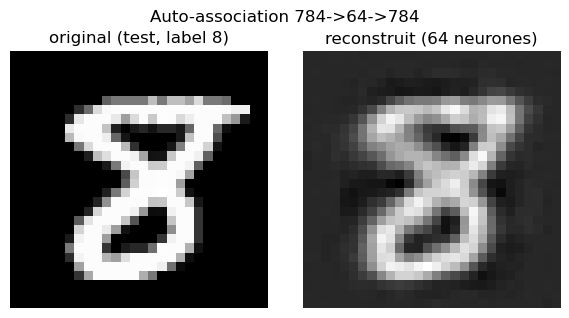

In [159]:
#autoenc = mlp.predict(X_test_FR)
#recon = reconstruct(autoenc, X_test_FR)

img_idx = 0                     # image de test choisie
img = X_test[img_idx]
#img_rec = reconstruct(autoenc, img[None, :]).reshape(28, 28)
img_rec = mlp.predict(img[None, :]).reshape(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
axes[0].imshow(img.reshape(28, 28), cmap="gray")
axes[0].set_title(f"original (test, label {y_test[img_idx]})")
axes[1].imshow(img_rec, cmap="gray")
axes[1].set_title(f"reconstruit ({n_hidden} neurones)")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Auto-association 784->{n_hidden}->784")
fig.tight_layout()
plt.savefig("images/image1_autoencodage.png", dpi=300, bbox_inches="tight")
#plt.close(fig)


#### 2. AdaBoost sur l'embedding

Création des datasets embed

In [145]:
E_train_FR = embed(mlp, X_train_FR)
E_test_FR = embed(mlp, X_test_FR)
print(f"Embedding train: {E_train_FR.shape}, test: {E_test_FR.shape}")

Embedding train: (8000, 64), test: (2000, 64)


In [160]:
E_train = embed(mlp, X_train)
E_test = embed(mlp, X_test)
print(f"Embedding train: {E_train.shape}, test: {E_test.shape}")

Embedding train: (52500, 64), test: (17500, 64)


Paramètres à tester

In [161]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [1, 2, 5, 10, 20, 50]}

Gridsearch sur l'embedding.

In [162]:
from sklearn.model_selection import GridSearchCV

results_embed = []
best_results_embed = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(E_train, y_train)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results_embed.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results_embed)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results_embed.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    y_pred = best.predict(E_test)
    acc_test = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. Accuracy = {acc_test}.")
    plt.savefig(f"images/cm_AdaBoost/cm_embedding_{estimator_name}.png", dpi=300, bbox_inches="tight")
    plt.close()

[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7007619047619047), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7007619047619047), 'n_estimators': 50}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.8299047619047618), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7007619047619047), 'n_estimators': 50}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.8299047619047618), 'n_estimators': 50}, {'estimator': 'tree_d20', 'accuracy': np.float64(0.9416952380952381), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 

<img src="images/cm_AdaBoost/cm_embedding_stump.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d2.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d5.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d20.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_embedding_perceptron.png" alt= "Matrice de confusion perceptron" width="500">

In [163]:
df_cv_all_embed = pd.concat(results_embed, ignore_index=True)
df_accuracy_embed = (df_cv_all_embed.rename(columns={"param_n_estimators": "n_estimators", "mean_test_score": "accuracy_cv", "std_test_score": "std_cv"})[["estimator", "n_estimators", "accuracy_cv", "std_cv"]].sort_values(["estimator", "n_estimators"]).reset_index(drop=True))
df_accuracy_embed.to_csv("results/AdaBoost_cv_results_embed.csv", sep=";") # transformation en csv
df_accuracy_embed

,estimator,n_estimators,accuracy_cv,std_cv
0,perceptron,1,0.841924,0.024005
1,perceptron,2,0.841924,0.024005
2,perceptron,5,0.839162,0.014330
3,perceptron,10,0.853619,0.008061
4,perceptron,20,0.842171,0.005947
5,perceptron,50,0.840629,0.007473
6,stump,1,0.179010,0.001349
7,stump,2,0.170762,0.003306
8,stump,5,0.210248,0.020672
9,stump,10,0.323410,0.018405


In [165]:
df_best_results_embed = pd.DataFrame(best_results_embed, columns=["estimator", "accuracy", "n_estimators"])
df_best_results_embed.to_csv("results/AdaBoost_cv_best_results_embed.csv", sep=";") # transformation en csv
df_best_results_embed

,estimator,accuracy,n_estimators
0,stump,0.584057,50
1,tree_d2,0.700762,50
2,tree_d5,0.829905,50
3,tree_d20,0.941695,50
4,perceptron,0.853619,10


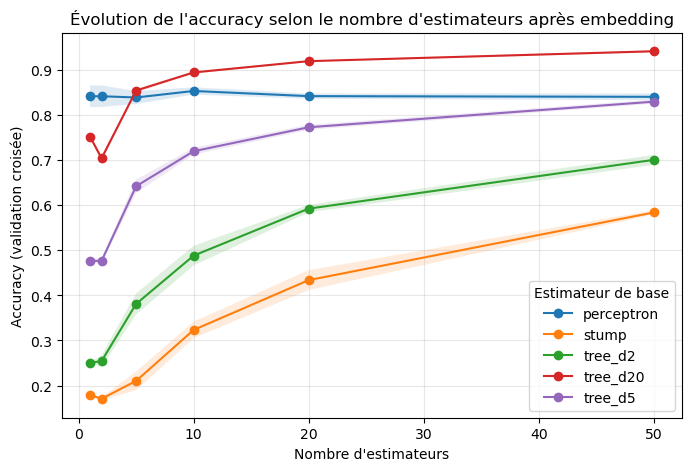

In [166]:
fig, ax = plt.subplots(figsize=(8, 5))

for estimator_name, sub in df_accuracy_embed.groupby("estimator"):
    ax.plot(sub["n_estimators"], sub["accuracy_cv"],
            marker="o", label=estimator_name)
    ax.fill_between(sub["n_estimators"],
                    sub["accuracy_cv"] - sub["std_cv"],
                    sub["accuracy_cv"] + sub["std_cv"],
                    alpha=0.15)

ax.set_xlabel("Nombre d'estimateurs")
ax.set_ylabel("Accuracy (validation croisée)")
ax.set_title("Évolution de l'accuracy selon le nombre d'estimateurs après embedding")
ax.legend(title="Estimateur de base")
ax.grid(True, alpha=0.3)
plt.savefig("images/graphs/accuracy_vs_n_estimators_embed.png", dpi=300, bbox_inches="tight")
plt.show()

### 3. Saliency map